In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"
columns = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel_Length",
    "Kernel_Width",
    "Asymmetry",
    "Groove_Length",
    "Class"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns
)


In [3]:
print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)
display(df.head())

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("Missing values in each column:")
print(df.isnull().sum())



Dataset loaded successfully!
Shape of dataset: (210, 8)


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area           210 non-null    float64
 1   Perimeter      210 non-null    float64
 2   Compactness    210 non-null    float64
 3   Kernel_Length  210 non-null    float64
 4   Kernel_Width   210 non-null    float64
 5   Asymmetry      210 non-null    float64
 6   Groove_Length  210 non-null    float64
 7   Class          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Statistical Summary:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Class
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


Missing values in each column:
Area             0
Perimeter        0
Compactness      0
Kernel_Length    0
Kernel_Width     0
Asymmetry        0
Groove_Length    0
Class            0
dtype: int64


In [4]:
X = df.drop("Class", axis=1)
print("Features used for DBSCAN:")
print(X.columns.tolist())



Features used for DBSCAN:
['Area', 'Perimeter', 'Compactness', 'Kernel_Length', 'Kernel_Width', 'Asymmetry', 'Groove_Length']


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Data standardized successfully.")
print("First five standardized observations:")
display(pd.DataFrame(X_scaled, columns=X.columns).head())



Data standardized successfully.
First five standardized observations:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length
0,0.142098,0.215462,0.000061,0.304218,0.141702,-0.986152,-0.383577
1,0.011188,0.008224,0.428515,-0.168625,0.197432,-1.788166,-0.922013
2,-0.192067,-0.360201,1.442383,-0.763637,0.208048,-0.667479,-1.189192
3,-0.347091,-0.475333,1.039381,-0.688978,0.319508,-0.960818,-1.229983
4,0.445257,0.330595,1.374509,0.066666,0.805159,-1.563495,-0.475356


In [6]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)
labels = dbscan.fit_predict(X_scaled)

df["Cluster"] = labels
print("DBSCAN clustering completed.")
print("Unique labels:", np.unique(labels))



DBSCAN clustering completed.
Unique labels: [-1  0  1  2]


In [7]:
cluster_counts = df["Cluster"].value_counts().sort_index()
print("Number of points in each cluster:")
print(cluster_counts)

Number of points in each cluster:
Cluster
-1     59
 0    107
 1     15
 2     29
Name: count, dtype: int64


In [8]:
noise_count = int(np.sum(labels == -1))
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", noise_count)

noise_points = df[df["Cluster"] == -1]
print("Noise Points:")
display(noise_points)


Number of clusters: 3
Number of noise points: 59
Noise Points:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Class,Cluster
4,16.14,14.99,0.9034,5.658,3.562,1.3550,5.175,1,-1
8,16.63,15.46,0.8747,6.053,3.465,2.0400,5.877,1,-1
9,16.44,15.25,0.8880,5.884,3.505,1.9690,5.533,1,-1
12,13.89,14.02,0.8880,5.439,3.199,3.9860,4.738,1,-1
15,14.59,14.28,0.8993,5.351,3.333,4.1850,4.781,1,-1
16,13.99,13.83,0.9183,5.119,3.383,5.2340,4.781,1,-1
17,15.69,14.75,0.9058,5.527,3.514,1.5990,5.046,1,-1
18,14.70,14.21,0.9153,5.205,3.466,1.7670,4.649,1,-1
23,12.08,13.23,0.8664,5.099,2.936,1.4150,4.961,1,-1
30,13.16,13.82,0.8662,5.454,2.975,0.8551,5.056,1,-1


In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)
print("Total variance represented:",
      round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio:
[0.71874303 0.17108184]
Total variance represented: 0.8898


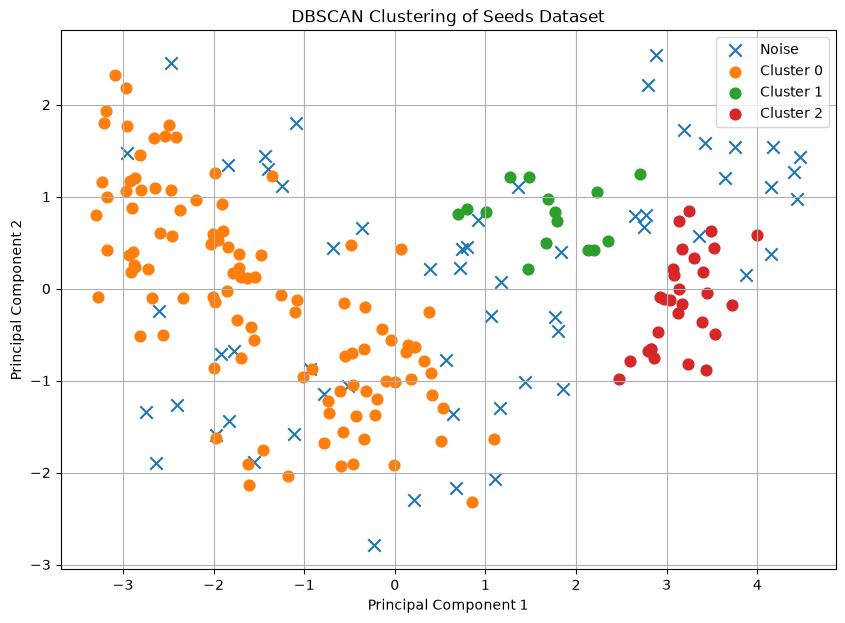

In [10]:
plt.figure(figsize=(10, 7))
unique_labels = sorted(set(labels))
for label in unique_labels:
    cluster_points = X_pca[labels == label]
    if label == -1:
        marker = "x"
        size = 80
        label_name = "Noise"
    else:
        marker = "o"
        size = 60
        label_name = f"Cluster {label}"
    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        marker=marker,
        s=size,
        label=label_name
    )
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering of Seeds Dataset")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
non_noise = labels != -1
if n_clusters >= 2 and np.sum(non_noise) > n_clusters:
    score = silhouette_score(
        X_scaled[non_noise],
        labels[non_noise]
    )
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated because DBSCAN")
    print("produced fewer than two valid clusters.")

Silhouette Score: 0.3755


In [12]:
comparison = pd.crosstab(
    df["Class"],
    df["Cluster"]
)
print("Actual Class vs DBSCAN Cluster:")
display(comparison)

Actual Class vs DBSCAN Cluster:


Cluster,-1,0,1,2
Class,,,,
1,22,48,0,0
2,26,0,15,29
3,11,59,0,0


In [13]:
print("=" * 55)
print("DBSCAN CLUSTERING SUMMARY")
print("=" * 55)
print("Total observations     :", len(df))
print("Number of features     :", X.shape[1])
print("Number of clusters     :", n_clusters)
print("Number of noise points :", noise_count)
print("\nCluster-wise distribution:")
print(cluster_counts)
print("=" * 55)

DBSCAN CLUSTERING SUMMARY
Total observations     : 210
Number of features     : 7
Number of clusters     : 3
Number of noise points : 59

Cluster-wise distribution:
Cluster
-1     59
 0    107
 1     15
 2     29
Name: count, dtype: int64


In [14]:
eps_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
results = []
for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=5)
    temp_labels = model.fit_predict(X_scaled)
    temp_clusters = len(set(temp_labels)) - (1 if -1 in temp_labels else 0)
    temp_noise = int(np.sum(temp_labels == -1))
    results.append({
        "eps": eps,
        "clusters": temp_clusters,
        "noise_points": temp_noise
    })
results_df = pd.DataFrame(results)
display(results_df)

,eps,clusters,noise_points
0,0.5,1,205
1,0.6,5,161
2,0.7,7,78
3,0.8,3,59
4,0.9,1,28
5,1.0,1,13
